In [1]:
#EXERCISE 1
import numpy as np
from scipy import signal

def mean_filter(image, size):
    kernel = np.ones((size, size)) / (size * size)    # mean kernel
    return signal.convolve2d(image, kernel, mode='same', boundary='symm')   # 2D convolution


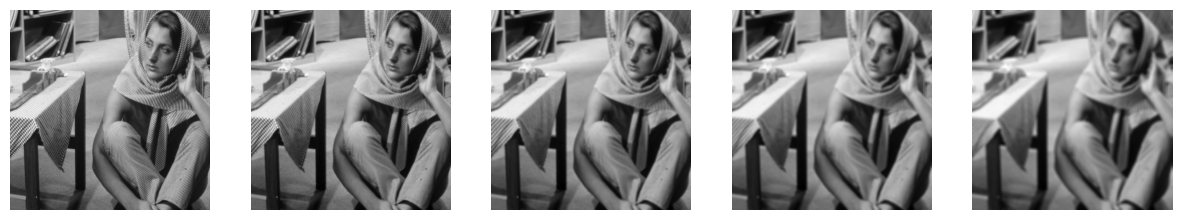

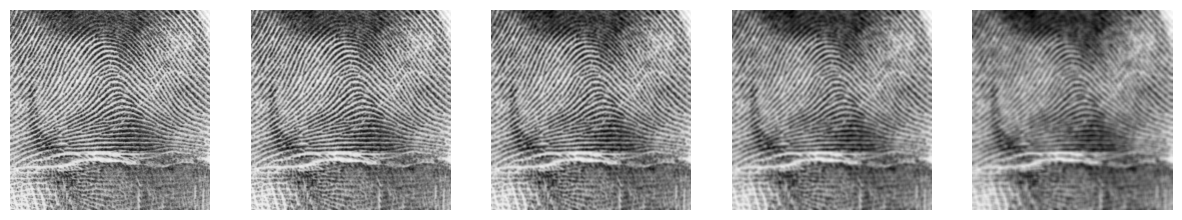

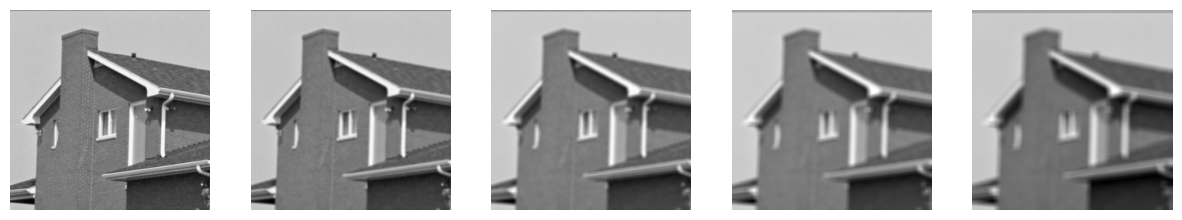

In [2]:
#EXERCISE 2
import numpy as np
import matplotlib.pyplot as plt

names = ["barbara", "fingerprint", "house"]
sizes = [3, 5, 7, 9]

for name in names:
    image = plt.imread(name + ".png")
    if image.ndim == 3:
        image = image[:, :, 0]
    plt.figure(figsize=(15, 3.5))
    plt.subplot(1, 5, 1)
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    for i, size in enumerate(sizes):
        result = mean_filter(image, size)
        plt.imsave(name + "_mean_" + str(size) + ".png", result, cmap='gray')   # save result
        plt.subplot(1, 5, i + 2)
        plt.imshow(result, cmap='gray')
        plt.axis('off')
    plt.show()


In [3]:
#EXERCISE 3
import numpy as np
from scipy import signal

def sobel_edges(image):
    hx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])    # Sobel mask, horizontal gradient
    hy = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])    # Sobel mask, vertical gradient
    gx = signal.convolve2d(image, hx, mode='same', boundary='symm')
    gy = signal.convolve2d(image, hy, mode='same', boundary='symm')
    return np.sqrt(gx**2 + gy**2)                           # gradient magnitude


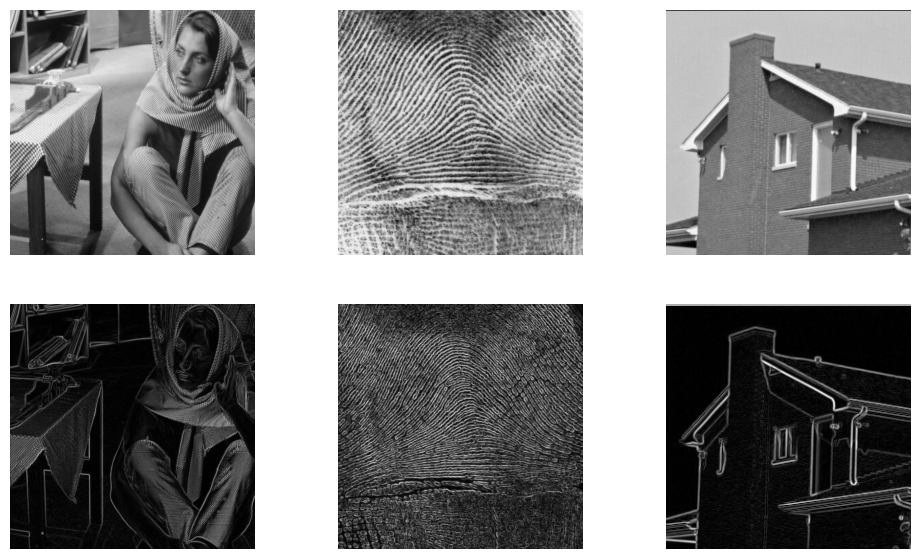

In [4]:
#EXERCISE 4
import numpy as np
import matplotlib.pyplot as plt

names = ["barbara", "fingerprint", "house"]

plt.figure(figsize=(12, 7))
for i, name in enumerate(names):
    image = plt.imread(name + ".png")
    if image.ndim == 3:
        image = image[:, :, 0]
    edges = sobel_edges(image)
    plt.imsave(name + "_sobel.png", edges, cmap='gray')
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    plt.subplot(2, 3, i + 4)
    plt.imshow(edges, cmap='gray')
    plt.axis('off')
plt.show()


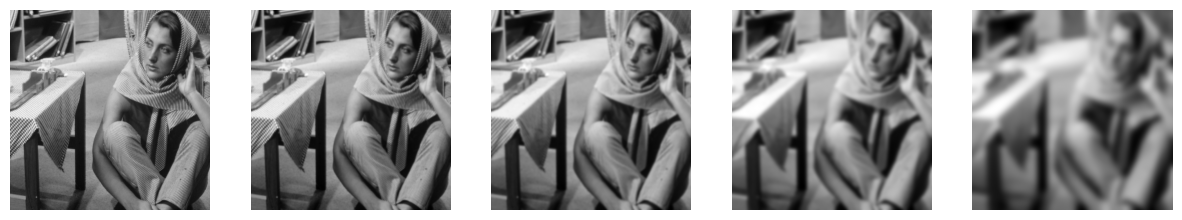

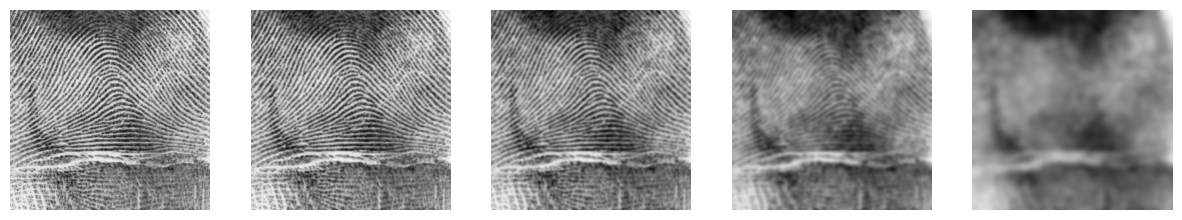

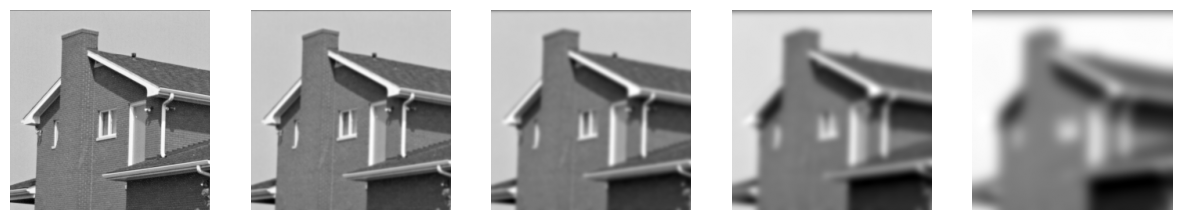

In [5]:
#EXERCISE 5
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import gaussian    # gaussian filter function from scikit-image

names = ["barbara", "fingerprint", "house"]
sigmas = [1, 2, 4, 8]

for name in names:
    image = plt.imread(name + ".png")
    if image.ndim == 3:
        image = image[:, :, 0]
    plt.figure(figsize=(15, 3.5))
    plt.subplot(1, 5, 1)
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    for i, sigma in enumerate(sigmas):
        result = gaussian(image, sigma=sigma)
        plt.imsave(name + "_gauss_" + str(sigma) + ".png", result, cmap='gray')
        plt.subplot(1, 5, i + 2)
        plt.imshow(result, cmap='gray')
        plt.axis('off')
    plt.show()


noisy 26.03439481142584
mean 23.30762761345095
gaussian 25.281439373300564


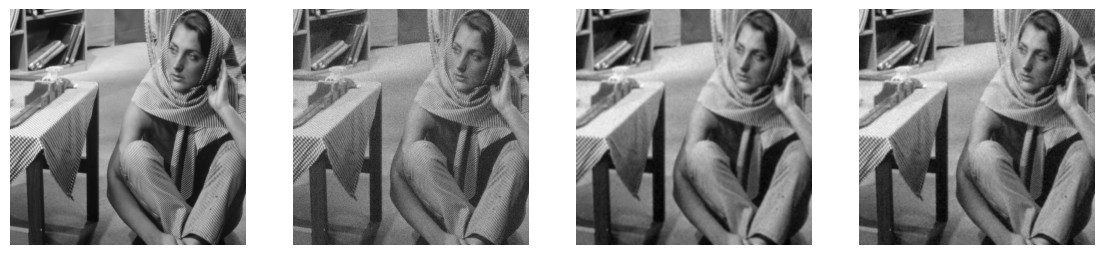

In [6]:
#EXERCISE 6
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from skimage.filters import gaussian
from skimage.metrics import peak_signal_noise_ratio

image = plt.imread("barbara.png")
if image.ndim == 3:
    image = image[:, :, 0]

np.random.seed(0)
noisy = image + np.random.normal(0, 0.05, image.shape)    # gaussian noise, standard deviation 0.05

kernel = np.ones((5, 5)) / 25
mean_result = signal.convolve2d(noisy, kernel, mode='same', boundary='symm')    # mean filter 5x5
gauss_result = gaussian(noisy, sigma=1, truncate=2)                             # gaussian, window 5x5

print("noisy", peak_signal_noise_ratio(image, noisy, data_range=1))
print("mean", peak_signal_noise_ratio(image, mean_result, data_range=1))
print("gaussian", peak_signal_noise_ratio(image, gauss_result, data_range=1))

plt.figure(figsize=(14, 4))
for i, im in enumerate([image, noisy, mean_result, gauss_result]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(im, cmap='gray')
    plt.axis('off')
plt.show()
